# Quick study: one call from folder to tables

`run_study` runs a whole temperature study: it works out which file is which, drops stored spectra acquired with other settings, picks NIST lines per element, removes the baseline, integrates, and builds the ratio and scatter tables. You choose four things:

| | here |
|---|---|
| **folder** | `data/end_to_end` |
| **how files map to element / sample / temperature** | a pattern (or a manifest CSV) |
| **elements** | Ce, Gd |
| **baseline** | `'snip'` or `'airpls'` |

It needs the NIST database once (`libs-viewer nist build`). [end_to_end_temp_study.ipynb](end_to_end_temp_study.ipynb) walks through the same steps one by one.

In [1]:
from pathlib import Path

import libs_viewer.libs as LV
from libs_viewer.libs.plotting import plot_baseline, plot_spectrum, plot_study

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())

## 1. Check the file mapping

The pattern is matched against every `.tdms` path under the folder. `{element}`, `{sample}` and `{temperature}` are captured, and `*` stands for any text within one folder or file name. Here `Ce/1_wt%/Ce1_300C.tdms` gives element Ce, sample `1_wt%` and temperature 300.

Listing the temperatures also catches names where the temperature is glued to other digits (`Ce1400.tdms` → 400). Any file that doesn't match raises an error, so nothing is silently guessed. `study_plan` shows the mapping before anything is analysed:

In [2]:
FOLDER = ROOT / 'data' / 'end_to_end'
PATTERN = '{element}/{sample}/*{temperature}*'
TEMPERATURES = [300, 350, 400]

LV.study_plan(FOLDER, pattern=PATTERN, temperatures=TEMPERATURES)

,file,element,sample,temperature,use_columns
0,Ce/1_wt%/Ce1_300C.tdms,Ce,Ce 1_wt%,300,None
1,Ce/1_wt%/Ce1 350 new location.tdms,Ce,Ce 1_wt%,350,None
2,Ce/1_wt%/Ce1400.tdms,Ce,Ce 1_wt%,400,None
3,Ce/5_wt%/Ce_Sample2_Temp_300C.tdms,Ce,Ce 5_wt%,300,None
4,Ce/5_wt%/Ce_Sample2_Temp_350C.tdms,Ce,Ce 5_wt%,350,None
5,Ce/5_wt%/Ce_Sample2_Temp_400C.tdms,Ce,Ce 5_wt%,400,None
6,Gd/1_wt%/Gd_Sample1_300.tdms,Gd,Gd 1_wt%,300,None
7,Gd/1_wt%/Gd_Sample1_350.tdms,Gd,Gd 1_wt%,350,None
8,Gd/1_wt%/Gd_Sample1_400.tdms,Gd,Gd 1_wt%,400,None
9,Gd/5_wt%/Gd_Sample5_300_3.5delay.tdms,Gd,Gd 5_wt%,300,None


## 2. Run it

In [3]:
result = LV.run_study(FOLDER, elements=['Ce', 'Gd'], baseline='snip',
                      pattern=PATTERN, temperatures=TEMPERATURES)
print(result.summary())

LIBS temperature study: C:\Users\Jack\Desktop\Academic GitHub Repos\LIBS_Viewer\data\end_to_end
elements Ce, Gd | baseline snip | reference 300 C | 12 files, 4 samples

Lines:
  Ce 1_wt%: Ce II 418.66, Ce II 413.76
  Ce 5_wt%: Ce II 418.66, Ce II 399.92, Ce II 401.24, Ce II 413.76
  Gd 1_wt%: Gd II 342.25, Gd II 364.62, Gd II 358.50, Gd II 335.05
  Gd 5_wt%: Gd II 342.25, Gd II 364.62, Gd II 358.50, Gd II 335.05

R_rel (line share of total light, relative to the reference):
Temperature (C)              300    350    400
sample   row                                  
Ce 1_wt% Ce II 418.66        1.0  0.864  1.567
         Ce II 413.76        1.0  1.026  1.564
         Total               1.0  0.970  1.237
         Total (excl. sat.)  1.0  0.811  1.187
Ce 5_wt% Ce II 418.66        1.0  1.116  0.615
         Ce II 399.92        1.0  1.154  0.538
         Ce II 401.24        1.0  1.108  0.598
         Ce II 413.76        1.0  1.116  0.584
         Total               1.0  1.132  0.962
    

`notes` lists everything the run decided on its own, and anything odd the loader found in the files. Here:

- it dropped location 2 of `Gd_Sample5_300_3.5delay.tdms` (10 single shots at 1.0 µs and 10 mJ instead of 3.5 µs and 80 mJ);
- three samples were recorded differently at different temperatures (accumulated vs single shots, 1 vs 2 locations). Their per-shot averages still compare; their scatter values don't.

## 3. Tables

All tables are indexed by sample, then line (or *Total*), with one column per temperature.

In [4]:
result.r_rel.round(3)          # line share of the total light, relative to 300 °C

Temperature (C)              300    350    400
sample   row                                  
Ce 1_wt% Ce II 418.66        1.0  0.864  1.567
         Ce II 413.76        1.0  1.026  1.564
         Total               1.0  0.970  1.237
         Total (excl. sat.)  1.0  0.811  1.187
Ce 5_wt% Ce II 418.66        1.0  1.116  0.615
         Ce II 399.92        1.0  1.154  0.538
         Ce II 401.24        1.0  1.108  0.598
         Ce II 413.76        1.0  1.116  0.584
         Total               1.0  1.132  0.962
         Total (excl. sat.)  1.0  1.211  0.953
Gd 1_wt% Gd II 342.25        1.0  0.120  0.063
         Gd II 364.62        1.0  0.121  0.070
         Gd II 358.50        1.0  0.122  0.052
         Gd II 335.05        1.0  0.111  0.061
         Total               1.0  0.375  0.363
         Total (excl. sat.)  1.0  0.256  0.222
Gd 5_wt% Gd II 342.25        1.0  0.667  0.599
         Gd II 364.62        1.0  0.730  0.567
         Gd II 358.50        1.0  0.700  0.592
         Gd II 335.05        1.0  0.681  0.536
         Total               1.0  0.921  0.197
         Total (excl. sat.)  1.0  0.935  0.167

In [5]:
result.areas.round(1)          # raw areas (counts·nm per shot); result.r_direct = A(T) / A(300)

Temperature (C)                    300        350       400
sample   row                                               
Ce 1_wt% Ce II 418.66             49.8       41.7      96.5
         Ce II 413.76             48.1       47.8      93.0
         Total                263795.2   255833.7  326238.0
         Total (excl. sat.)   217962.9   176685.3  258726.4
Ce 5_wt% Ce II 418.66           1675.2     2116.7     991.0
         Ce II 399.92            390.8      510.5     202.1
         Ce II 401.24            549.9      689.6     316.5
         Ce II 413.76           1378.0     1741.2     773.6
         Total               1007921.2  1140970.6  969168.9
         Total (excl. sat.)   666356.1   807232.6  635239.9
Gd 1_wt% Gd II 342.25           2555.5      114.8      58.7
         Gd II 364.62           1872.9       85.1      47.6
         Gd II 358.50           1529.1       70.1      29.0
         Gd II 335.05           1872.9       78.2      41.5
         Total               1499162.9   562830.6  543983.2
         Total (excl. sat.)   965322.6   246898.7  214207.4
Gd 5_wt% Gd II 342.25           2873.8     1767.1     339.1
         Gd II 364.62           2904.1     1953.0     324.6
         Gd II 358.50           1893.2     1221.5     220.8
         Gd II 335.05           2439.8     1531.4     258.0
         Total               1362233.2  1255102.9  268587.8
         Total (excl. sat.)  1194614.5  1117433.8  199886.6

In [6]:
result.overview                # how every file was recorded (only the spectra used)

,locations,spectra,shots per location,stored as,energy (mJ),gate delay (us),mixed settings
file,,,,,,,
Ce/1_wt%/Ce1_300C.tdms,2,20,10,single shots,80.0,1.0,
Ce/1_wt%/Ce1 350 new location.tdms,2,20,10,single shots,80.0,1.0,
Ce/1_wt%/Ce1400.tdms,2,20,10,single shots,80.0,1.0,
Ce/5_wt%/Ce_Sample2_Temp_300C.tdms,1,1,5,accumulated,80.0,3.5,
Ce/5_wt%/Ce_Sample2_Temp_350C.tdms,1,1,5,accumulated,80.0,3.5,
Ce/5_wt%/Ce_Sample2_Temp_400C.tdms,2,10,5,single shots,80.0,3.5,
Gd/1_wt%/Gd_Sample1_300.tdms,2,2,5,accumulated,80.0,2.5,
Gd/1_wt%/Gd_Sample1_350.tdms,1,1,5,accumulated,80.0,2.5,
Gd/1_wt%/Gd_Sample1_400.tdms,1,1,5,accumulated,80.0,2.5,


`scatter` shows how much single measurements spread, as a coefficient of variation (%):

- *location CV*: between the mean spectra of different locations (needs 2+ locations);
- *shot CV*: between single shots at the same location (needs single-shot files).

With only 2 locations per file here, the location CV is a rough number.

In [7]:
result.scatter.round(1)

locations  spectra  location CV, lines (%)  \
sample   temperature                                               
Ce 1_wt% 300                  2       20                    54.5   
         350                  2       20                   105.3   
         400                  2       20                   108.6   
Ce 5_wt% 400                  2       10                    79.3   
Gd 1_wt% 300                  2        2                   121.0   
Gd 5_wt% 350                  2       10                    60.7   
         400                  2       10                    89.3   

                      location CV, Total (%)  shot CV, lines (%)  \
sample   temperature                                               
Ce 1_wt% 300                            65.6                77.9   
         350                            52.2               181.1   
         400                            17.5                86.7   
Ce 5_wt% 400                            56.3                92.8   
Gd 1_wt% 300                            69.5                 NaN   
Gd 5_wt% 350                            75.6                15.7   
         400                            31.9                86.7   

                      shot CV, Total (%)  
sample   temperature                      
Ce 1_wt% 300                        25.1  
         350                        40.9  
         400                        17.1  
Ce 5_wt% 400                        52.6  
Gd 1_wt% 300                         NaN  
Gd 5_wt% 350                         6.5  
         400                        31.3

In [8]:
result.line_tables['Ce'][['label', 'intensity', 'status', 'detected_in']].head(12)

,label,intensity,status,detected_in
0,Ce I 569.92,1000,no peak in spectrum,[]
1,Ce II 418.66,1000,picked,"[Ce 1_wt%, Ce 5_wt%]"
2,Ce II 395.25,900,interference: Gd I 395.34,[]
3,Ce II 399.92,800,picked,[Ce 5_wt%]
4,Ce II 413.38,800,interference: Gd I 413.42,[]
5,Ce I 516.15,800,blended (neighbour line too close) / no peak i...,[]
6,Ce II 401.24,800,picked,[Ce 5_wt%]
7,Ce II 394.27,800,near saturated region,[]
8,Ce I 515.97,800,blended (neighbour line too close) / no peak i...,[]
9,Ce I 569.70,800,interference: Gd I 569.62,[]


## 4. Figures

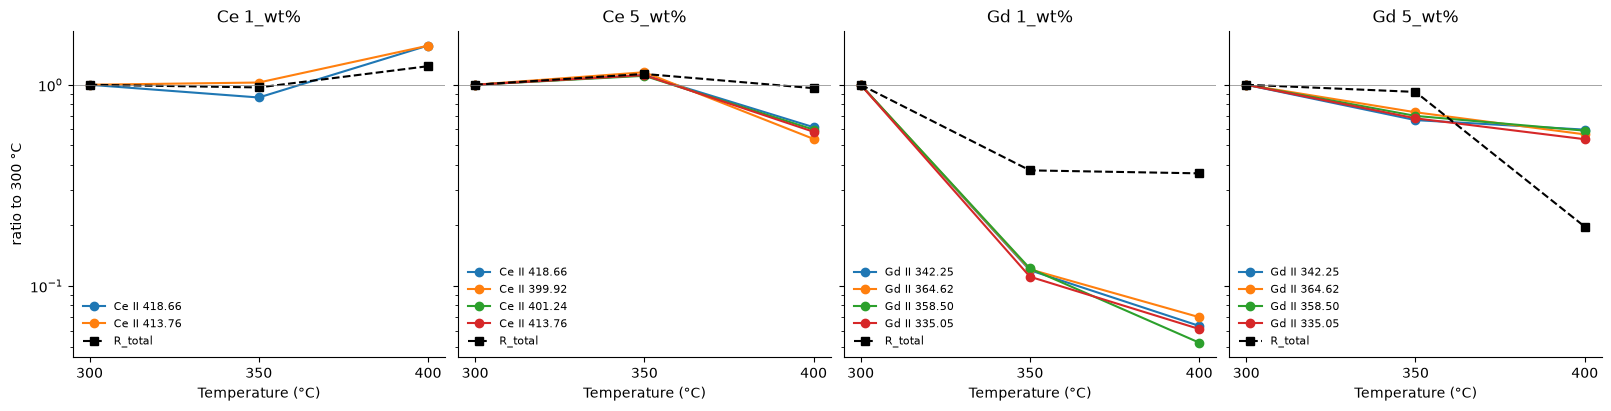

In [9]:
plot_study(result)

Check the baseline on one spectrum. The top panel shows the fitted continuum; the bottom one is what the *Total* area integrates. Change `method` to compare SNIP and airPLS.

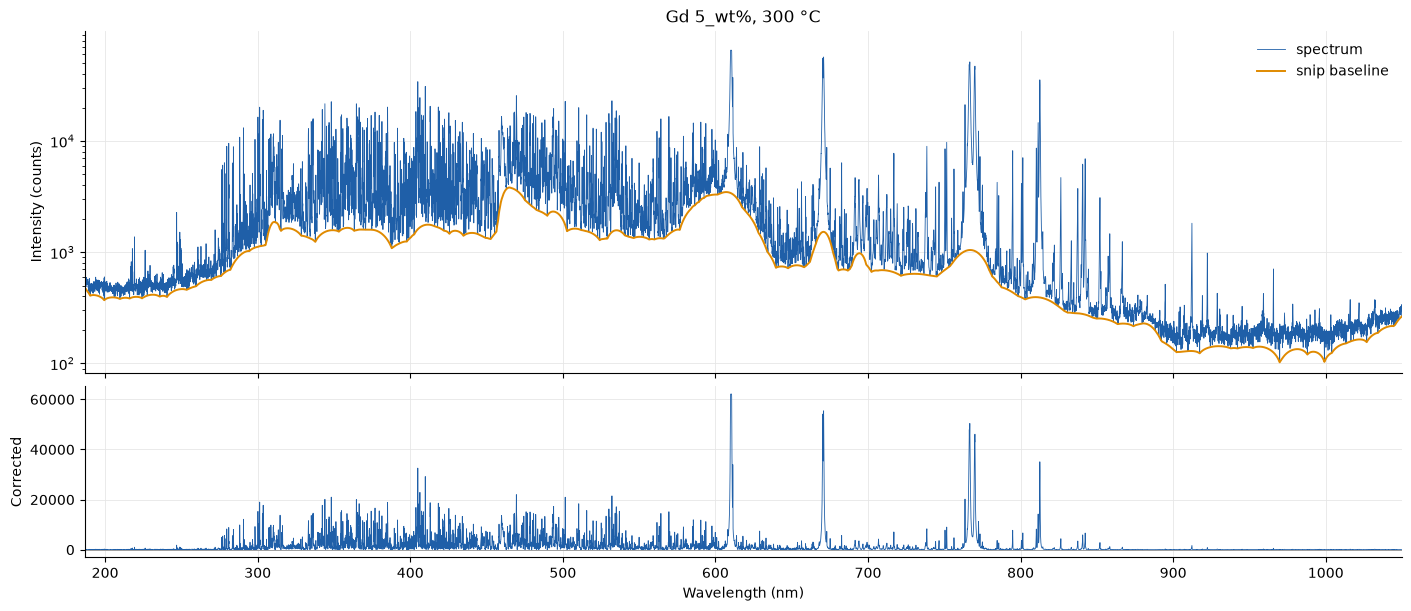

In [10]:
plot_baseline(result.wl, result.spectra['Gd 5_wt%'][300], method=result.settings['baseline'],
              title='Gd 5_wt%, 300 °C')

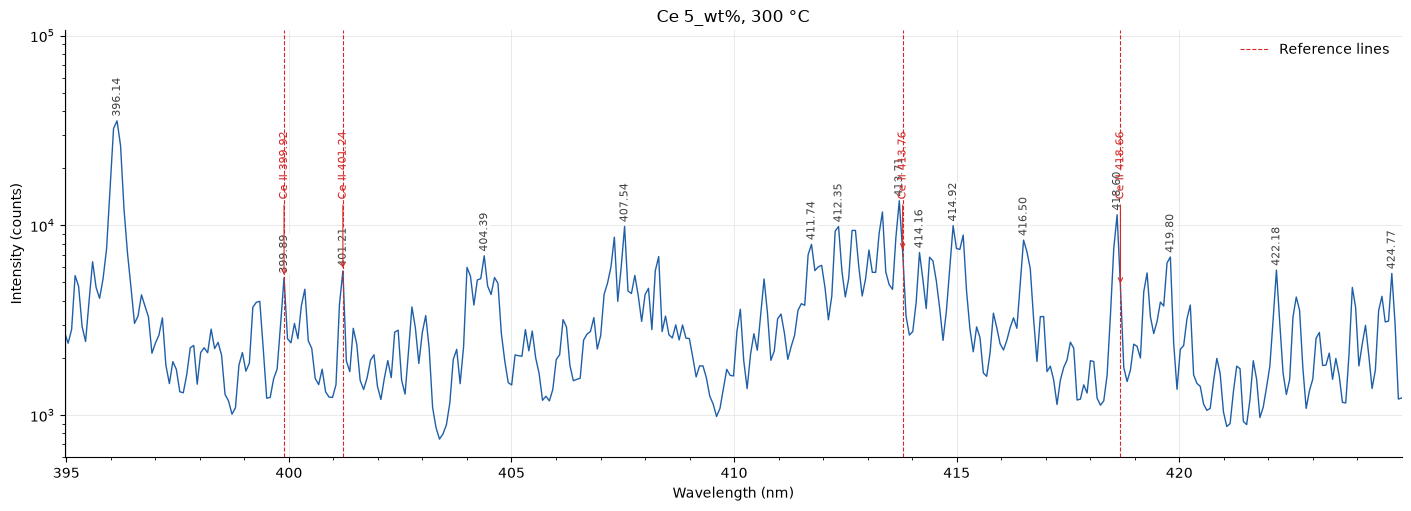

In [11]:
plot_spectrum(result.wl, result.spectra['Ce 5_wt%'][300], ref_lines=result.lines['Ce 5_wt%'],
              wl_range=(395, 425), title='Ce 5_wt%, 300 °C')

## 5. Save

`save` writes every table as CSV, plus `settings.json` (inputs, versions, picked lines, notes) and `summary.txt`. It refuses to write inside the data folder. `output/` is ignored by git.

In [12]:
written = result.save(ROOT / 'output' / 'end_to_end_snip')
[p.name for p in written]

['plan.csv',
 'overview.csv',
 'areas.csv',
 'R_direct.csv',
 'R_rel.csv',
 'scatter.csv',
 'lines_Ce.csv',
 'lines_Gd.csv',
 'settings.json',
 'summary.txt']

## Same thing from a terminal

```
libs-viewer analyze data/end_to_end --pattern "{element}/{sample}/*{temperature}*" ^
    --temperatures 300 350 400 --elements Ce Gd --baseline snip --out output/end_to_end_snip
```

Use `--manifest study.csv` (columns `file, element, sample, temperature[, use_columns]`) instead of `--pattern` when the file names have no usable pattern.